# Outlier Analysis
An outlier is a data point that is unusually far away from most of the other observations in a dataset. It may represent a genuine unusual event, a measurement problem, or an error in the data.

## What is an Outlier?
Definition
An outlier is a data point that is unusually far away from most of the other observations in a dataset. It may represent a genuine unusual event, a measurement problem, or an error in the data.
### Real-world example
- Most students score between 50 and 90 marks, but one student scores 5 marks.
- Most people spend ₹200–₹2,000 per shopping order, but one customer spends ₹1,00,000.
### Business example
- Most products sell 100–500 units per month, but one product sells 10,000 units.
- Most deliveries take 1–3 days, but one delivery takes 30 days.
### AI/ML use case
Outlier analysis helps identify unusual observations that may distort statistical summaries, affect Machine Learning models, or reveal fraud, equipment failures, and unusual customer behavior.

In [1]:
%mamba install pandas

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 4.015 seconds
  Name           Version  Build                Channel
--------------------------------------------------------------------
+ pandas         3.1.0    np23py313h124dbc7_0  emscripten-forge-4x
+ python-tzdata  2026.5   pyh5ded981_0         conda-forge
- pip            26.2.1   pyh145f28c_0         conda-forge


In [2]:
import pandas as pd

df = pd.DataFrame({
    "Salary": [25000, 28000, 30000, 32000, 35000, 200000]
})

print("Mean:", df["Salary"].mean())
print("Median:", df["Salary"].median())
print("Maximum:", df["Salary"].max())

Mean: 58333.333333333336
Median: 31000.0
Maximum: 200000


### Explanation of the code
- DataFrame() creates a dataset containing six salary values.
- mean() calculates the average salary, which is pulled upward by the unusually high value.
- median() calculates the middle value and is less affected by the high salary.
- max() identifies the largest value.
- The salary of ₹2,00,000 is a potential outlier, but it could be a genuine salary and should be investigated before removal.

## Why Outliers Occur
Definition
Outliers can occur because of data-entry mistakes, measurement errors, unusual events, natural variation, or genuine extreme observations. Understanding their cause helps us decide how to handle them correctly.
### Real-world example
- A person's weight is entered as 850 kg instead of 85 kg.
- A temperature sensor records an unusually high reading during an equipment malfunction.
### Business example
- An employee's salary is accidentally entered as ₹5,00,000 instead of ₹50,000.
- A retailer experiences a genuine sales spike during a major festival or clearance sale.
### AI/ML use case
Identifying the cause of an outlier helps prevent incorrect data cleaning and improves model reliability. It can also reveal fraud, operational problems, or important rare events.

In [3]:
import pandas as pd

df = pd.DataFrame({
    "Order_ID": [101, 102, 103, 104, 105],
    "Order_Amount": [500, 700, 650, 800, 70000]
})

print(df)
print("\nMean:", df["Order_Amount"].mean())

   Order_ID  Order_Amount
0       101           500
1       102           700
2       103           650
3       104           800
4       105         70000

Mean: 14530.0


### Explanation of the code
- The dataset contains five order amounts.
- The ₹70,000 order is much larger than the others.
- mean() calculates an average of ₹14,530, which is substantially higher than most orders.
- The high amount could be a genuine bulk purchase or a data-entry error.
- Checking the original transaction before making changes is the correct approach.

## Types of Outliers
Definition
Outliers can be classified according to how they appear in the data and how many variables are involved. Common categories include point outliers, contextual outliers, collective outliers, univariate outliers, and multivariate outliers.
### Real-world example
- A temperature of 45°C may be unusual in a particular city during winter but normal in another location during summer.
- A sudden series of unusual heart-rate readings may be more meaningful together than any single reading by itself.
### Business example
- A transaction of ₹5,00,000 may be unusual compared with ordinary retail purchases.
- A sudden increase in failed transactions over several minutes may indicate a system problem or suspicious activity.
### AI/ML use case
Understanding outlier types helps data scientists choose appropriate detection methods, such as IQR, Z-score, Isolation Forest, or multivariate anomaly detection.

In [5]:
import pandas as pd

df = pd.DataFrame({
    "Daily_Sales": [100, 110, 105, 115, 500]
})

mean = df["Daily_Sales"].mean()
std = df["Daily_Sales"].std()

df["Z_Score"] = ((df["Daily_Sales"] - mean) / std).round(2)

print(df)

   Daily_Sales  Z_Score
0          100    -0.49
1          110    -0.43
2          105    -0.46
3          115    -0.40
4          500     1.79


### Explanation of the code
- mean() calculates average daily sales.
- std() calculates the sample standard deviation.
- The Z-score measures how many standard deviations each observation is from the mean.
- The value 500 is much higher than the other sales values, but its Z-score is only 1.60 because the extreme value itself increases the mean and standard deviation.
- This demonstrates why the Z-score method can miss outliers in small datasets.

## Univariate Outliers
Definition
Univariate outlier analysis identifies unusual values by examining one variable at a time. It uses the distribution of a single feature to detect observations that are unusually high or low.
### Real-world example
- Identify unusually high or low marks in a classroom.
- Detect unusually large weights or heights in a population dataset.
### Business example
- Identify unusually high order amounts in an e-commerce dataset.
- Find products with unusually high monthly sales compared with other products.
### AI/ML use case
Univariate outlier detection is a useful preprocessing step for numerical features before training regression, clustering, or distance-based models.

In [6]:
import pandas as pd

df = pd.DataFrame({
    "Sales": [100, 110, 105, 115, 120, 500]
})

Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df["Sales"] < lower) |
    (df["Sales"] > upper)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower)
print("Upper Bound:", upper)
print("Outliers:")
print(outliers)

Q1: 106.25
Q3: 118.75
IQR: 12.5
Lower Bound: 87.5
Upper Bound: 137.5
Outliers:
   Sales
5    500


### Explanation of the code
- quantile(0.25) calculates the first quartile (Q1).
- quantile(0.75) calculates the third quartile (Q3).
- IQR is the difference between Q3 and Q1.
- The lower and upper bounds are calculated using the 1.5 × IQR rule.
- Values outside those bounds are flagged as potential outliers.
- Here, 500 is flagged because it is above the upper bound of 137.5.

## Multivariate Outliers
Definition
A multivariate outlier is an observation that appears unusual when multiple variables are considered together. A value may look normal in each individual column but still represent an unusual combination of features.
### Real-world example
- A person may have a normal height and a normal weight individually, but their combination may be unusual for the population being studied.
- A vehicle may have a normal speed and normal engine temperature separately, but that combination may be unusual under specific operating conditions.
### Business example
- A customer may have a normal transaction amount and normal transaction frequency, but the combination of location, amount, and timing may be suspicious.
- A product may have a normal price and normal sales volume individually, but an unusual combination of price, returns, and demand may indicate a problem.
### AI/ML use case
Multivariate outlier detection can help identify fraudulent transactions, abnormal machine behavior, unusual customer patterns, and anomalies that single-feature checks may miss.

In [ ]:
import pandas as pd
from sklearn.ensemble import IsolationForest

df = pd.DataFrame({
    "Amount": [100, 110, 95, 105, 120, 1000],
    "Transactions": [2, 3, 2, 2, 3, 20]
})

model = IsolationForest(
    contamination=1/6,
    random_state=42
)

df["Prediction"] = model.fit_predict(
    df[["Amount", "Transactions"]]
)

df["Result"] = df["Prediction"].map({
    1: "Normal",
    -1: "Potential Outlier"
})

print(df)

### Explanation of the code
- IsolationForest is an unsupervised Machine Learning algorithm for anomaly detection.
- contamination=1/6 tells the model to expect approximately one outlier among six observations.
- random_state=42 makes the random process reproducible.
- fit_predict() analyzes the two numerical features together.
- A prediction of 1 means normal, while -1 means a potential outlier.
- This method can identify unusual combinations that simple single-column checks may miss.

## Outlier Detection Techniques
### Technique 1: IQR Method
Definition
The Interquartile Range (IQR) method identifies potential outliers using the middle 50% of the data. It flags values below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR.
\[
IQR = Q3 - Q1
\]

\[
\text{Lower bound}=Q1-1.5(IQR)
\]

\[
\text{Upper bound}=Q3+1.5(IQR)
\]

### Real-world example
- Detect unusually high examination marks or unusually low marks in a class.
- Find unusually large weights in a dataset of people.
### Business example
- Detect unusually high transaction amounts in a retail dataset.
- Identify products whose monthly sales are far outside the normal range.
### AI/ML use case
IQR is useful for robust outlier detection because it is less influenced by extreme values than methods based on the mean and standard deviation.

In [8]:
import pandas as pd

data = pd.Series([10, 12, 13, 14, 15, 16, 18, 100])

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = data[(data < lower) | (data > upper)]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Bounds:", lower, upper)
print("Outliers:", outliers.tolist())

Q1: 12.75
Q3: 16.5
IQR: 3.75
Bounds: 7.125 22.125
Outliers: [100]


### Explanation of the code
- pd.Series() creates a single numerical variable.
- quantile() calculates Q1 and Q3.
- Subtracting Q1 from Q3 gives the IQR.
- The lower and upper bounds define the range of values that are not flagged by the 1.5 × IQR rule.
- The value 100 exceeds the upper bound of 24.625 and is flagged as a potential outlier.

## Technique 2: Z-Score Method
Definition
The Z-score method measures how many standard deviations a value lies from the mean. A common rule of thumb is to flag observations with an absolute Z-score greater than 3, although the appropriate threshold depends on the data and distribution.
\[
z=\frac{x-\mu}{\sigma}
\]

### Real-world example
- Identify examination marks that are unusually far above or below the class average.
- Find unusually high temperature readings compared with a sensor's typical measurements.
### Business example
- Identify sales values that are several standard deviations above the average.
- Detect unusually high delivery costs compared with the normal delivery-cost distribution.
### AI/ML use case
Z-scores help standardize numerical features and identify extreme values, particularly when the data is approximately normally distributed and the mean and standard deviation are meaningful summaries.

In [9]:
import pandas as pd
from scipy.stats import zscore

df = pd.DataFrame({
    "Sales": [100, 110, 105, 115, 120, 500]
})

df["Z_Score"] = zscore(df["Sales"])

outliers = df[df["Z_Score"].abs() > 2]

print(df.round(2))
print("\nPotential Outliers:")
print(outliers.round(2))

   Sales  Z_Score
0    100    -0.52
1    110    -0.45
2    105    -0.48
3    115    -0.41
4    120    -0.38
5    500     2.23

Potential Outliers:
   Sales  Z_Score
5    500     2.23


### Explanation of the code
- zscore() calculates standardized scores using the dataset's mean and population standard deviation by default.
- Positive Z-scores indicate values above the mean; negative scores indicate values below it.
- .abs() calculates the absolute Z-score, allowing unusually high and unusually low values to be flagged.
- > 2 applies the threshold selected for this example. A threshold of 3 is also commonly used.
- Z-scores can be misleading for highly skewed data or small samples because extreme values influence the mean and standard deviation.

## Technique 3: Box Plot
Definition
A box plot visualizes the distribution of a numerical variable using quartiles, the median, and whiskers. Under the standard 1.5 × IQR rule, observations beyond the whiskers are displayed as potential outliers.
### Real-world example
- Visualize unusually high marks in a classroom.
- Compare body-weight distributions across different age groups.
### Business example
- Compare delivery times across courier companies and identify unusually delayed deliveries.
- Compare salaries across departments to spot extreme observations.
### AI/ML use case
Box plots are useful during Exploratory Data Analysis (EDA) to visually detect potential outliers and compare distributions before data preprocessing.

In [11]:
%mamba install seaborn

mambajs 0.21.4

Specs: xeus-python, numpy, matplotlib, pillow, ipywidgets>=8.1.6, ipyleaflet, scipy, pandas, seaborn
Channels: emscripten-forge-4x, conda-forge

Solving environment...
Solving took 4.382 seconds
  Name          Version  Build                Channel
-------------------------------------------------------------------
+ patsy         1.0.3    py313h1804a44_0      emscripten-forge-4x
+ seaborn       0.13.2   hd8ed1ab_3           conda-forge
+ seaborn-base  0.13.2   pyhd8ed1ab_3         conda-forge
+ statsmodels   0.15.0   np23py313h07ed413_0  emscripten-forge-4x


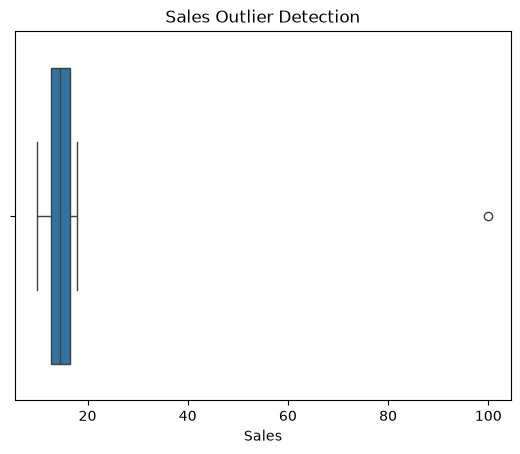

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Sales": [10, 12, 13, 14, 15, 16, 18, 100]
})

sns.boxplot(data=df, x="Sales")
plt.title("Sales Outlier Detection")
plt.show()

### Explanation of the code
- The DataFrame contains one numerical variable, Sales.
- sns.boxplot() displays its median, quartiles, and whiskers.
- The box represents the middle 50% of the data.
- Points beyond the whiskers are potential outliers according to the box-plot rule.
- plt.show() displays the chart.

## Technique 4: Scatter Plot
Definition
A scatter plot displays the relationship between two numerical variables using individual points. It can reveal observations that are far from the main pattern or that have unusual combinations of values.
### Real-world example
- Plot height against weight to identify unusual combinations.
- Compare temperature and electricity usage to identify unusual readings.
### Business example
- Plot transaction amount against transaction frequency to identify unusual customer activity.
- Compare product price and sales volume to detect unusual products.
### AI/ML use case
Scatter plots help detect multivariate outliers visually, explore clusters, and investigate observations that may affect regression or classification models.

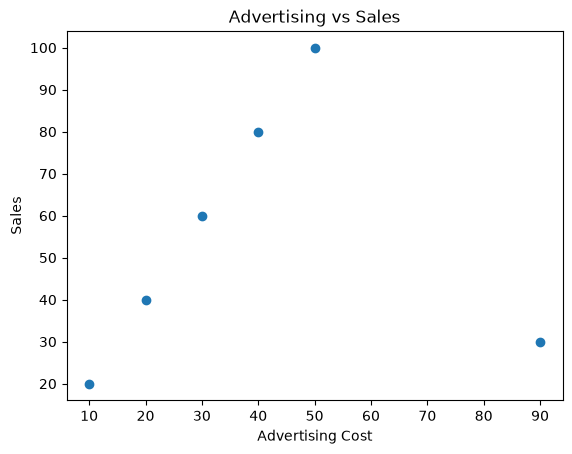

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "Advertising": [10, 20, 30, 40, 50, 90],
    "Sales": [20, 40, 60, 80, 100, 30]
})

plt.scatter(df["Advertising"], df["Sales"])
plt.xlabel("Advertising Cost")
plt.ylabel("Sales")
plt.title("Advertising vs Sales")
plt.show()

### Explanation of the code
- Advertising is plotted on the X-axis and Sales on the Y-axis.
- plt.scatter() displays each observation as a point.
- The point with advertising cost 90 and sales 30 is unusual relative to the other observations.
- This point may be a genuine business event, a recording error, or a result of other factors.
- A scatter plot can reveal unusual relationships but does not, by itself, establish whether a value is incorrect.

## What Should You Do With Detected Outliers?
Detecting an outlier does not mean you should automatically remove it. First, investigate why it occurred and decide how it should be handled.
### A. Is it a genuine observation?
Definition: A genuine observation is a value that accurately represents a real event or measurement, even if it is unusual compared with most data points.

### Real-world example: 
A student genuinely scores 5 marks when most students score above 50.

### Business example: 
An e-commerce customer places a genuine bulk order worth ₹1,00,000.

### AI/ML use case: 
Retaining genuine extreme observations can help a model learn about important rare cases, such as high-value customers or unusually large claims.

In [15]:
import pandas as pd

df = pd.DataFrame({
    "Order_ID": [101, 102, 103],
    "Amount": [500, 700, 100000],
    "Verified": [True, True, True]
})

print(df[df["Verified"]])

   Order_ID  Amount  Verified
0       101     500      True
1       102     700      True
2       103  100000      True


### Explanation of the code
- Verified represents whether the order has been checked against the original transaction record.
- Filtering on Verified returns all three verified orders.
- The high-value order is retained because it represents a genuine transaction.
- In a real project, verification should come from trusted records, not simply from assuming that a value is correct.

### B. Is it a data-entry error?
Definition: A data-entry error occurs when a value is recorded incorrectly due to a typing mistake, incorrect unit, faulty import, or other data-processing problem.

### Real-world example: 
A person's weight is entered as 850 kg instead of 85 kg.

### Business example: 
A product price is entered as ₹50,000 instead of ₹5,000.

### AI/ML use case: 
Correcting confirmed data errors prevents a model from learning misleading patterns and producing unreliable prediction

In [16]:
import pandas as pd

df = pd.DataFrame({
    "Product": ["A", "B", "C"],
    "Price": [500, 700, 50000]
})

# Correct only after verification
df.loc[df["Product"] == "C", "Price"] = 5000

print(df)

  Product  Price
0       A    500
1       B    700
2       C   5000


### Explanation of the code
- loc[] selects the row for product C.
- The price is changed to 5,000 based on the assumed verification result.
- The code demonstrates correction of a confirmed error, not automatic correction of every extreme value.
- Always preserve the original data or maintain an audit trail when correcting records.

### C. Is it unusual but valid?
Definition: An unusual but valid observation is an accurate value that occurs rarely because of natural variation, special circumstances, or exceptional events.

### Real-world example: 
A person runs a marathon much faster than most people in the dataset.

### Business example: 
A store experiences unusually high sales during a festival.
### AI/ML use case: 
Valid unusual observations can help models learn rare but important scenarios, including seasonal demand spikes and exceptional customer behavior.

In [17]:
import pandas as pd

df = pd.DataFrame({
    "Day": ["Monday", "Tuesday", "Festival"],
    "Sales": [10000, 12000, 80000]
})

print(df)

        Day  Sales
0    Monday  10000
1   Tuesday  12000
2  Festival  80000


### Explanation of the code
- The dataset records daily sales.
- Festival sales are much higher than ordinary daily sales.
- If transaction records confirm the sales, the value is valid and should not automatically be removed.
- Adding a feature such as Is_Festival may help a Machine Learning model explain the difference.

## D. Should it be removed?
Definition: Removing an outlier means excluding an observation from the analysis or training dataset. This should generally be done only when the value is erroneous, invalid for the task, or unsuitable for a clearly justified modeling purpose.

### Real-world example: 
A sensor record contains an impossible measurement caused by a confirmed malfunction.

### Business example: 
A test transaction accidentally included in a real sales dataset should be excluded from production sales analysis.

### AI/ML use case: 
Removing confirmed invalid records can improve data quality, but removing legitimate extreme cases may introduce bias or reduce model performance on rare events.

In [18]:
import pandas as pd

df = pd.DataFrame({
    "Sales": [100, 110, 105, 115, 999999]
})

# Assume 999999 is a verified test record
clean_df = df[df["Sales"] != 999999]

print(clean_df)

   Sales
0    100
1    110
2    105
3    115


### Explanation of the code
- The original DataFrame contains five observations.
- The filter excludes the value 999999 because the example assumes it is a confirmed test record.
- The filtered dataset contains only valid production sales.
- In a real workflow, use a verified record identifier or an explicit data-quality flag rather than removing a value simply because it is large.

## E. Should it be transformed?
Definition: Transforming an outlier means applying a mathematical operation to a feature to reduce skewness or change its scale without necessarily deleting the observation. Common techniques include logarithmic and square-root transformations.

### Real-world example: 
Household incomes often have a right-skewed distribution because a small number of people earn much more than others.

### Business example: 
Order amounts may range from small everyday purchases to very large corporate orders.

### AI/ML use case: 
Transformations can help regression models handle skewed numerical features and reduce the influence of extreme magnitudes. The effect depends on the model and the data distribution.

In [19]:
import pandas as pd
import numpy as np

df = pd.DataFrame({
    "Order_Amount": [100, 200, 500, 1000, 100000]
})

df["Log_Amount"] = np.log1p(df["Order_Amount"])

print(df.round(2))

   Order_Amount  Log_Amount
0           100        4.62
1           200        5.30
2           500        6.22
3          1000        6.91
4        100000       11.51


### Explanation of the code
- np.log1p() calculates the natural logarithm of one plus each order amount.
- Log_Amount stores the transformed values.
- The transformed scale reduces the relative distance between small and large observations.
- All original observations remain represented.
- Keep the original feature when needed, and apply transformations consistently to training and future data.

## F. Should it be retained?
Definition: Retaining an outlier means keeping a valid observation in the dataset because it represents meaningful information. This is often appropriate when extreme events are part of the real problem being modeled.

### Real-world example: 
A genuine medical measurement that is unusually high may be important for identifying a health risk.

### Business example: 
A verified high-value customer purchase may be essential for understanding revenue and customer lifetime value.

### AI/ML use case: 
Retaining valid extreme observations helps models learn from rare events, particularly in fraud detection, risk modeling, demand forecasting, and anomaly detection.

In [20]:
import pandas as pd

df = pd.DataFrame({
    "Customer": ["A", "B", "C"],
    "Purchase": [500, 700, 100000]
})

# All purchases are verified
retained_df = df.copy()

print(retained_df)

  Customer  Purchase
0        A       500
1        B       700
2        C    100000


### Explanation of the code
- copy() creates a separate copy of the dataset.
- All three verified purchases are retained, including the high-value purchase.
- The example shows that outlier treatment is a decision based on context, not just a statistical threshold.
- Depending on the task, a robust model or a transformed feature may be preferable to deleting a valid observation.